<center><h1>Park_Peter_HW4</h1></center>
<br>
<br>

Name: Peter Park
<br>
Github Username: pspark1052
<br>
USC ID: 4240400712

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Get the AReM Data Set

In [2]:
activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
columns = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

instances = []

for activity in activities:
    for num in range(1, 16):
        path = "data/AReM/" + activity + "/dataset" + str(num) + ".csv"
        if os.path.exists(path):
            df = pd.read_csv(path, comment="#", header=None, sep=r"[,\s]+",
                             engine="python", usecols=range(7), names=columns)
            instances.append([activity, num, df])

print(len(instances))

88


### (b) Splitting Data

In [3]:
train = []
test = []

for inst in instances:
    activity, num, df = inst
    if activity in ["bending1", "bending2"] and num <= 2:
        test.append(inst)
    elif activity not in ["bending1", "bending2"] and num <= 3:
        test.append(inst)
    else:
        train.append(inst)

print("Train:", len(train))
print("Test:", len(test))

Train: 69
Test: 19


### (c) Feature Extraction

In [4]:
rows = []
for activity, num, df in instances:
    row = []
    for col in columns[1:]:
        s = df[col]
        row += [s.min(), s.max(), s.mean(), s.median(), s.std(), s.quantile(0.25), s.quantile(0.75)]
    rows.append(row)

names = []
for i in range(1, 7):
    names += [f"min{i}", f"max{i}", f"mean{i}", f"median{i}", f"std{i}", f"1st quart{i}", f"3rd quart{i}"]

features = pd.DataFrame(rows, columns=names, index=range(1, 89))
print(features.shape)
features

(88, 42)


,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,mean2,...,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,0.358604,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,0.372437,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,0.426250,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,0.696042,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,0.535979,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,4.576562,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,4.456333,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,4.371958,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
87,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,0.0,14.82,4.380583,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

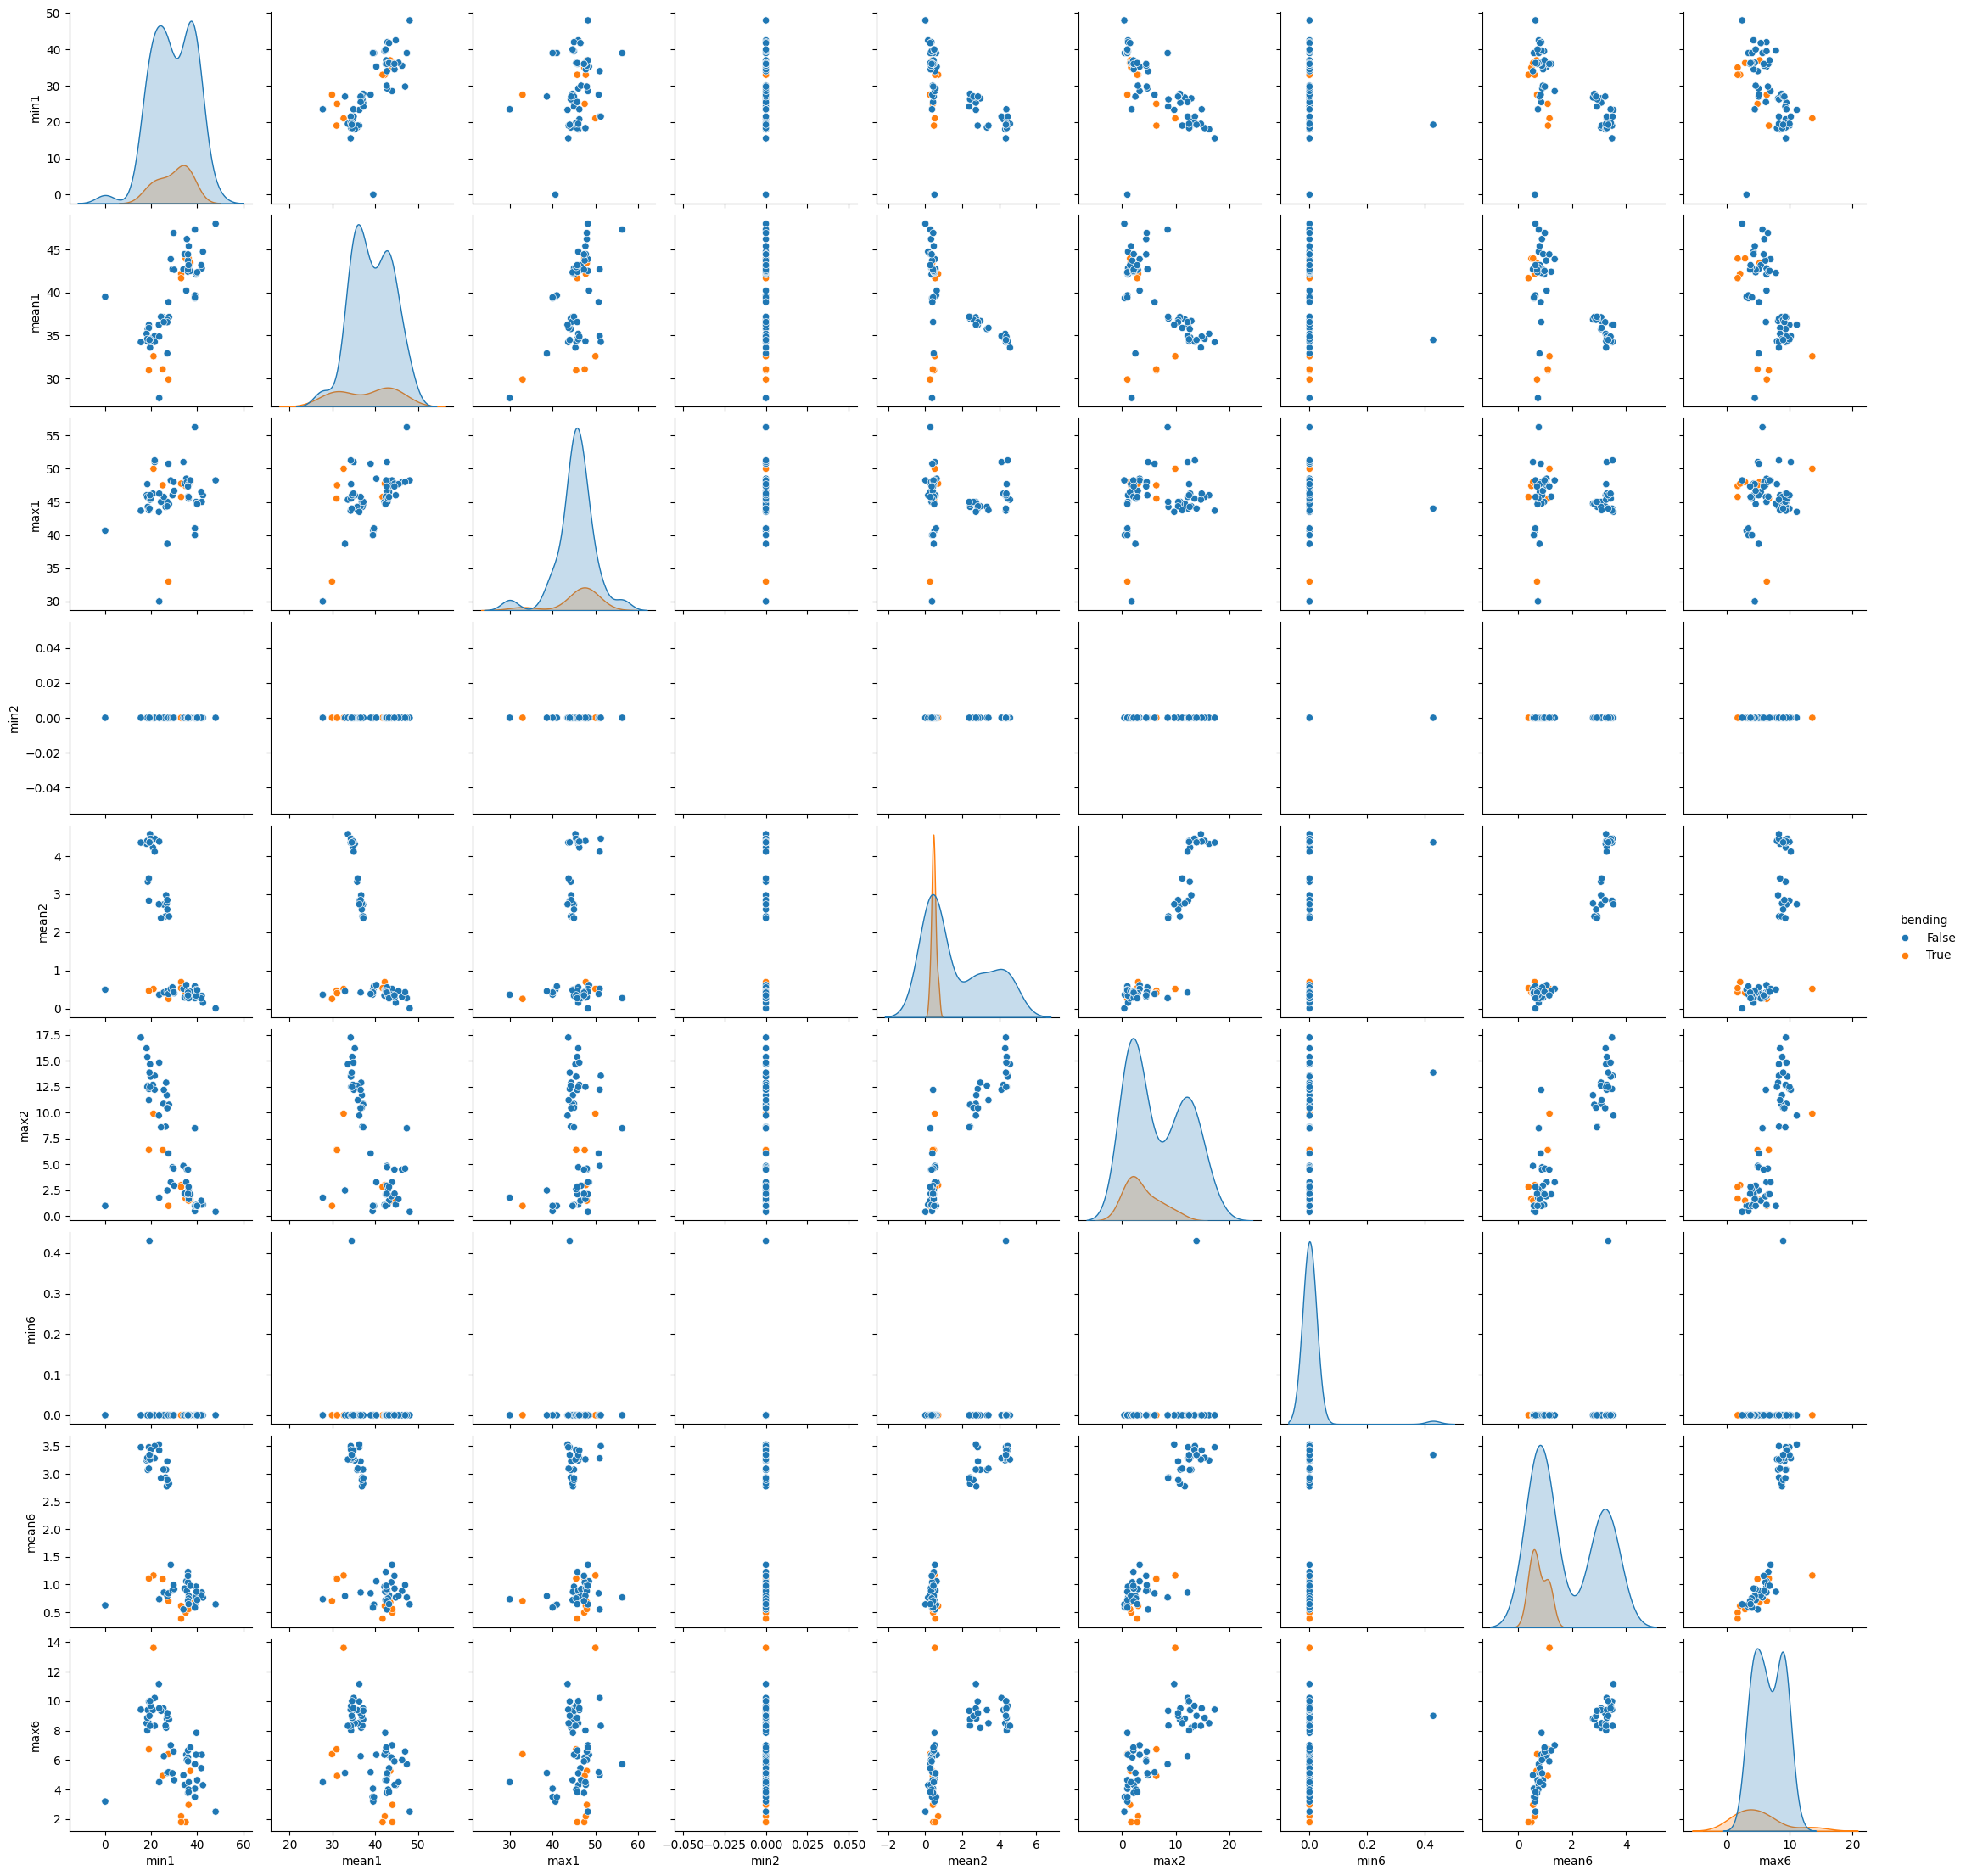

In [5]:
rows = []
labels = []
for activity, num, df in train:
    row = []
    for col in ["avg_rss12", "var_rss12", "var_rss23"]:
        s = df[col]
        row += [s.min(), s.mean(), s.max()]
    rows.append(row)
    labels.append(activity in ["bending1", "bending2"])

plot_df = pd.DataFrame(rows, columns=["min1", "mean1", "max1", "min2", "mean2", "max2", "min6", "mean6", "max6"])
plot_df["bending"] = labels
sns.pairplot(plot_df, hue="bending")
plt.show()

#### ii. Splitted Plots

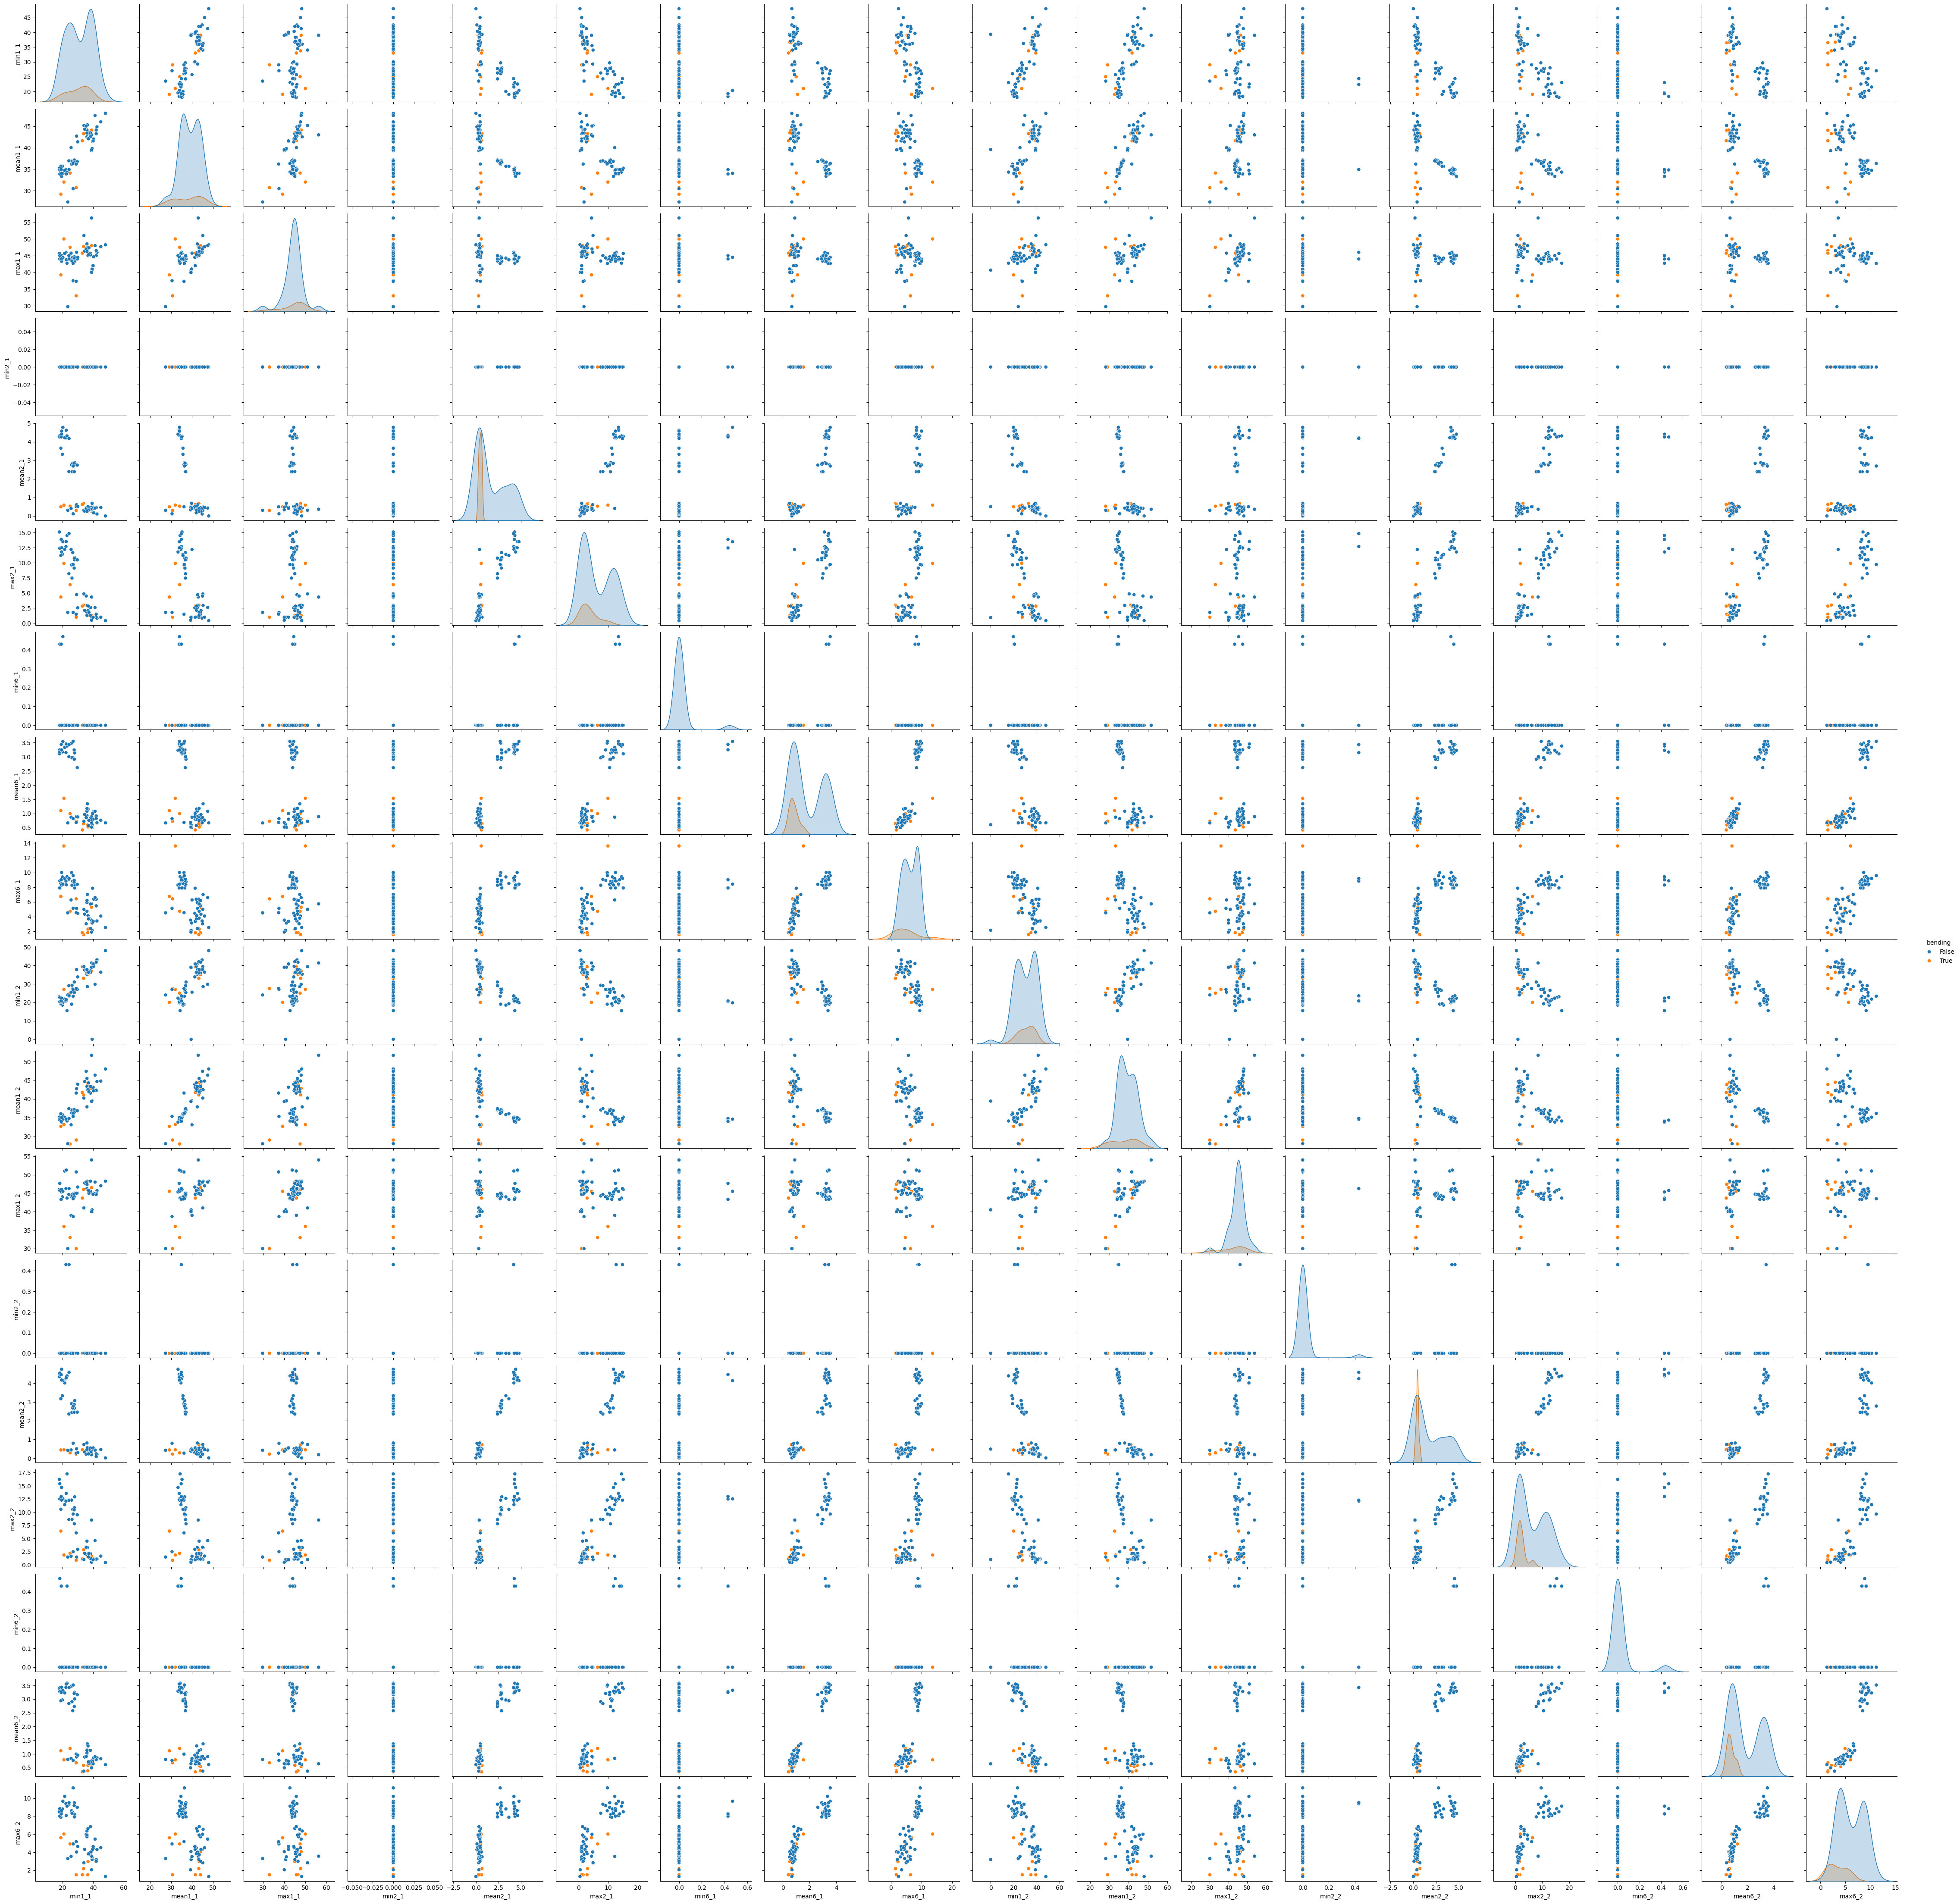

In [6]:
rows = []
for activity, num, df in train:
    h = len(df) // 2
    row = []
    for part in [df.iloc[:h], df.iloc[h:]]:
        for col in ["avg_rss12", "var_rss12", "var_rss23"]:
            row += [part[col].min(), part[col].mean(), part[col].max()]
    rows.append(row)

plot_df = pd.DataFrame(rows, columns=[f"{f}{i}_{p}" for p in [1, 2] for i in [1, 2, 6] for f in ["min", "mean", "max"]])
plot_df["bending"] = labels
sns.pairplot(plot_df, hue="bending")
plt.show()

There is no considerable difference from 2(a)i. The features from each half look very similar to the features from the whole time series, and bending and the other activities separate in about the same way.

#### iii. Time Series Segments

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

def get_features(data, l):
    rows = []
    for activity, num, df in data:
        row = []
        for idx in np.array_split(range(len(df)), l):
            for col in columns[1:]:
                s = df[col].iloc[idx]
                row += [s.min(), s.mean(), s.max()]
        rows.append(row)
    names = [f"{f}{i}_{j}" for j in range(1, l + 1) for i in range(1, 7) for f in ["min", "mean", "max"]]
    y = [activity in ["bending1", "bending2"] for activity, num, df in data]
    return pd.DataFrame(rows, columns=names), np.array(y)

cv = StratifiedKFold(5, shuffle=True, random_state=0)
results = []
for l in range(1, 21):
    X, y = get_features(train, l)
    rfecv = RFECV(LogisticRegression(penalty=None, max_iter=100), cv=cv).fit(X, y)
    results.append([l, rfecv.n_features_, rfecv.cv_results_["mean_test_score"].max()])

results = pd.DataFrame(results, columns=["l", "p", "CV accuracy"])
print(results)
print(results.loc[results["CV accuracy"].idxmax()])

     l   p  CV accuracy
0    1   4     1.000000
1    2  13     0.985714
2    3  14     0.971429
3    4   9     0.941758
4    5   1     0.941758
5    6   2     0.941758
6    7  16     0.985714
7    8  20     0.941758
8    9  23     0.956044
9   10   3     0.941758
10  11  10     0.985714
11  12  44     0.956044
12  13   6     0.956044
13  14  19     0.970330
14  15  23     0.970330
15  16  12     0.970330
16  17   4     0.970330
17  18   3     0.984615
18  19   4     0.984615
19  20  15     0.970330
l              1.0
p              4.0
CV accuracy    1.0
Name: 0, dtype: float64


Wrong way: choose the features using all of the training data, then cross-validate. The validation folds already helped pick the features, so the CV accuracy looks better than it really is.

Right way: choose the features inside each fold, using only that fold's training part, then test on the held-out part. RFECV does this. I used stratified folds so each fold has about the same share of bending instances, since bending is rare (9 of 69).

#### iv. Confusion Matrix

[[60  0]
 [ 0  9]]
AUC: 1.0


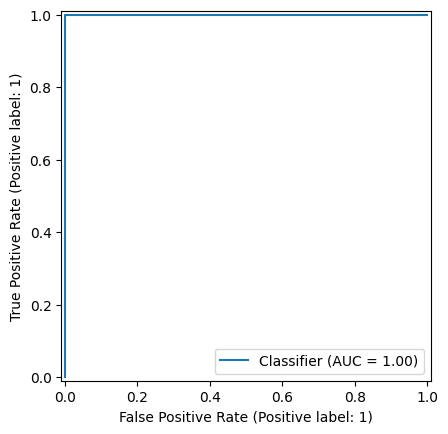

,Coef.,P>|z|
const,-8.026678,0.999999
mean1_1,-6.052127,0.999953
max2_1,-5.510293,0.999964
min5_1,7.066265,0.999936
max5_1,7.437310,0.999926


In [8]:
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.metrics import confusion_matrix, roc_auc_score, RocCurveDisplay
warnings.filterwarnings("ignore")

X, y = get_features(train, 1)
cols = X.columns[RFE(LogisticRegression(penalty=None, max_iter=100), n_features_to_select=4).fit(X, y).support_]

model = sm.Logit(y, sm.add_constant(X[cols])).fit(maxiter=100, disp=0)
prob = model.predict(sm.add_constant(X[cols]))

print(confusion_matrix(y, prob > 0.5))
print("AUC:", roc_auc_score(y, prob))
RocCurveDisplay.from_predictions(y, prob)
plt.show()
model.summary2().tables[1][["Coef.", "P>|z|"]]

#### v. Test Classifier

In [9]:
X_test, y_test = get_features(test, 1)
pred = model.predict(sm.add_constant(X_test[cols])) > 0.5
print(confusion_matrix(y_test, pred))
print("Test accuracy:", (pred == y_test).mean())

[[15  0]
 [ 0  4]]
Test accuracy: 1.0


The test accuracy is 1.0, the same as the cross-validation accuracy (1.0), so the model works just as well on new data.

#### vi. Separation

Yes. The classes are perfectly separated (100% accuracy on train, CV, and test), so the fit is unstable: there is no finite best set of coefficients. The coefficients stayed moderate only because max_iter=100 stopped the solver early, but their standard errors became huge, so every p-value is about 0.9999.

#### vii. Imbalance

[[60  0]
 [ 0  9]]
AUC: 1.0


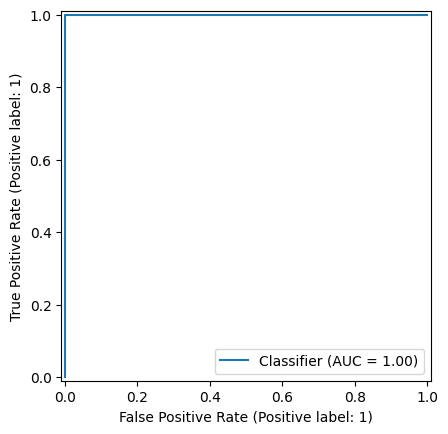

const     -45.745109
mean1_1    -4.087306
max2_1     -3.686771
min5_1      5.425366
max5_1      6.351246
dtype: float64

In [10]:
np.random.seed(0)
idx = np.r_[np.where(y)[0], np.random.choice(np.where(~y)[0], 9, replace=False)]
cc = sm.Logit(y[idx], sm.add_constant(X[cols].iloc[idx])).fit(maxiter=100, disp=0)
params = cc.params.copy()
params["const"] += np.log(9 / 60)
prob = cc.model.predict(params, sm.add_constant(X[cols]))

print(confusion_matrix(y, prob > 0.5))
print("AUC:", roc_auc_score(y, prob))
RocCurveDisplay.from_predictions(y, prob)
plt.show()
params

Yes, the classes are imbalanced (9 bending vs. 60 other in training, and 4 vs. 15 in test). I used case-control sampling. All 9 bending instances and 9 random non-bending instances, then adjusted the intercept by adding log(9/60).

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [11]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.preprocessing import StandardScaler

results = []
for l in range(1, 21):
    X, y = get_features(train, l)
    m = LogisticRegressionCV(Cs=10, cv=cv, penalty="l1", solver="liblinear").fit(StandardScaler().fit_transform(X), y)
    results.append([l, m.C_[0], m.scores_[True].mean(axis=0).max()])

results = pd.DataFrame(results, columns=["l", "C", "CV accuracy"])
print(results)
best = results.loc[results["CV accuracy"].idxmax()]
print(best)

l = int(best["l"])
X, y = get_features(train, l)
X_test, y_test = get_features(test, l)
scaler = StandardScaler().fit(X)
m = LogisticRegressionCV(Cs=10, cv=cv, penalty="l1", solver="liblinear").fit(scaler.transform(X), y)
print("Test accuracy:", m.score(scaler.transform(X_test), y_test))

     l             C  CV accuracy
0    1      2.782559     0.985714
1    2    166.810054     0.971429
2    3      0.359381     0.971429
3    4      0.359381     0.927473
4    5      2.782559     0.913187
5    6     21.544347     0.941758
6    7    166.810054     0.956044
7    8      2.782559     0.927473
8    9      2.782559     0.956044
9   10    166.810054     0.927473
10  11      2.782559     0.970330
11  12      2.782559     0.956044
12  13      2.782559     0.971429
13  14      2.782559     0.971429
14  15  10000.000000     0.941758
15  16     21.544347     0.956044
16  17      0.359381     0.941758
17  18      2.782559     0.971429
18  19     21.544347     0.956044
19  20    166.810054     0.956044
l              1.000000
C              2.782559
CV accuracy    0.985714
Name: 0, dtype: float64
Test accuracy: 0.9473684210526315


#### ii. Comparison

Variable selection (RFE, used instead of p-value pruning) performed slightly better. CV accuracy 1.0 and test accuracy 1.0, compared to 0.986 and 0.947 for L1-penalized logistic regression. L1 is easier to implement, because it picks features and tunes C automatically in one function, and it ran much faster (a few seconds vs. about a minute).

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

     l             C  CV accuracy
0    1      2.782559     0.882418
1    2      2.782559     0.853846
2    3  10000.000000     0.782418
3    4     21.544347     0.783516
4    5    166.810054     0.781319
5    6     21.544347     0.795604
6    7    166.810054     0.795604
7    8   1291.549665     0.812088
8    9     21.544347     0.767033
9   10     21.544347     0.768132
10  11   1291.549665     0.809890
11  12    166.810054     0.781319
12  13    166.810054     0.782418
13  14     21.544347     0.781319
14  15  10000.000000     0.780220
15  16  10000.000000     0.736264
16  17    166.810054     0.795604
17  18   1291.549665     0.764835
18  19     21.544347     0.795604
19  20    166.810054     0.752747
Best l: 1
Test error: 0.052631578947368474
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 1 0 2 0]
 [0 0 0 0 0 0 3]]
AUC (one-vs-rest): 1.0


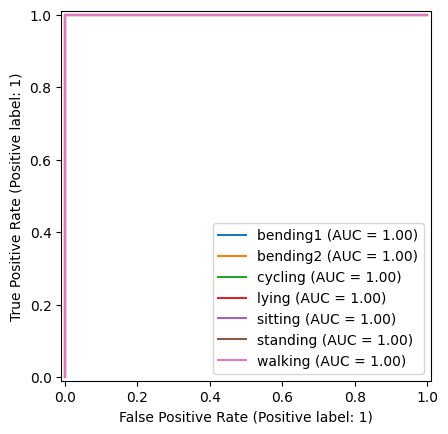

In [12]:
y = np.array([a for a, n, d in train])
y_test = np.array([a for a, n, d in test])

results = []
for l in range(1, 21):
    X = get_features(train, l)[0]
    m = LogisticRegressionCV(Cs=10, cv=cv, penalty="l1", solver="saga").fit(StandardScaler().fit_transform(X), y)
    results.append([l, m.C_[0], m.scores_["walking"].mean(axis=0).max()])

results = pd.DataFrame(results, columns=["l", "C", "CV accuracy"])
print(results)
l = int(results.loc[results["CV accuracy"].idxmax(), "l"])

X, X_test = get_features(train, l)[0], get_features(test, l)[0]
scaler = StandardScaler().fit(X)
m = LogisticRegressionCV(Cs=10, cv=cv, penalty="l1", solver="saga").fit(scaler.transform(X), y)
prob = m.predict_proba(scaler.transform(X_test))

print("Best l:", l)
print("Test error:", 1 - m.score(scaler.transform(X_test), y_test))
print(confusion_matrix(y_test, m.predict(scaler.transform(X_test)), labels=m.classes_))
print("AUC (one-vs-rest):", roc_auc_score(y_test, prob, multi_class="ovr"))
ax = plt.gca()
for i, c in enumerate(m.classes_):
    RocCurveDisplay.from_predictions(y_test == c, prob[:, i], name=c, ax=ax)
plt.show()

For multiclass problems, the confusion matrix has one row and one column per class. Rows are the true activity, columns are the predicted activity, and the diagonal shows correct predictions. ROC curves are made one-vs-rest: each activity gets its own curve (that activity vs. all others), and the AUC is the average of these.

#### ii. Naive Bayes

In [13]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.model_selection import cross_val_score

for nb in [GaussianNB(), MultinomialNB()]:
    scores = [cross_val_score(nb, get_features(train, l)[0], y, cv=cv).mean() for l in range(1, 21)]
    l = int(np.argmax(scores)) + 1
    X, X_test = get_features(train, l)[0], get_features(test, l)[0]
    nb.fit(X, y)
    print(type(nb).__name__, "- best l:", l, "CV accuracy:", max(scores))
    print("Test error:", 1 - nb.score(X_test, y_test))
    print("AUC (one-vs-rest):", roc_auc_score(y_test, nb.predict_proba(X_test), multi_class="ovr"))
    print(confusion_matrix(y_test, nb.predict(X_test), labels=nb.classes_))

GaussianNB - best l: 2 CV accuracy: 0.8549450549450549
Test error: 0.052631578947368474
AUC (one-vs-rest): 1.0
[[2 0 0 0 0 0 0]
 [0 2 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 3 0 0]
 [0 0 0 0 1 2 0]
 [0 0 0 0 0 0 3]]
MultinomialNB - best l: 7 CV accuracy: 0.798901098901099
Test error: 0.26315789473684215
AUC (one-vs-rest): 0.9791666666666667
[[2 0 0 0 0 0 0]
 [2 0 0 0 0 0 0]
 [0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0]
 [0 0 0 0 2 1 0]
 [0 0 0 1 1 1 0]
 [0 0 0 0 0 0 3]]


Gaussian Naive Bayes did much better than Multinomial Naive Bayes (test error 0.053 vs. 0.263). The features are continuous sensor values, which fit Gaussian's bell-curve assumption better. Multinomial is meant for count data, and it often mixed up the two bending types and sitting/standing.

#### ii. Comparison

L1-penalized multinomial regression is the best method for this problem. It tied with Gaussian Naive Bayes on test error (0.053) and AUC (1.0), but had a higher cross-validation accuracy (0.882 vs. 0.855). Multinomial Naive Bayes was clearly the worst.

## 3. ISLR 4.8.3

The Bayes classifier assigns x to the class with the largest $\pi_k f_k(x)$, where $f_k(x) = \dfrac{1}{\sqrt{2\pi}\,\sigma_k} e^{-(x-\mu_k)^2/(2\sigma_k^2)}$. Taking the log and dropping the constant gives the discriminant:

$\delta_k(x) = -\dfrac{x^2}{2\sigma_k^2} + \dfrac{\mu_k}{\sigma_k^2}x - \dfrac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k$

The boundary between two classes is where $\delta_1(x) = \delta_2(x)$. Moving everything to one side gives $ax^2 + bx + c = 0$, where

$a = \dfrac{1}{2\sigma_2^2} - \dfrac{1}{2\sigma_1^2}$

This is nonzero whenever $\sigma_1 \neq \sigma_2$, so the boundary has an $x^2$ term. The Bayes classifier is therefore quadratic, not linear.

## 4. ISLR 4.8.7

Using Bayes' theorem with the normal distribution (variance 36 for both groups):

P(dividend | X = 4) = (0.8 × e^(−(4−10)²/72)) / (0.8 × e^(−(4−10)²/72) + 0.2 × e^(−(4−0)²/72)) = 0.4852 / (0.4852 + 0.1601) ≈ 0.752

The probability is about 75.2%.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9